In [1]:
import pandas as pd 
import numpy as np

df = pd.read_csv("~/ML2FinalProject_Spring2026/Riot/match_data2.csv", header=None)
df.head()

df = df.to_numpy()


In [2]:
from collections import defaultdict
import datetime

per_player = []

for player in df:
    per_day = defaultdict(list)
    for i in range(1, len(player)-1):
        if pd.isna(player[i]):
            break
        dic = eval(player[i]) 
        day = dic['game_start'].date()
        per_day[day].append(player[i])
    per_player.append(per_day)


In [3]:
import pandas as pd

data = []
count = 0
for i in range(len(per_player)):
    player_id = f"player_{i}"
    
    for day, games in per_player[i].items():

        value = 0
        for game in games:
            value+=eval(game)['timePlayed']

        
        data.append({
            "date": pd.to_datetime(day),
            "player": player_id,
            "value": value
        })
    count = i

df = pd.DataFrame(data)

time_series = df.pivot(index="date", columns="player", values="value")

time_series = time_series.sort_index()

time_series = time_series.asfreq("D")



In [4]:
import math
time_series = time_series[:'2026-04-11':]
past_year = time_series['2026-03-27':]

not_playing = []
for i in range(16):
    if len(past_year) - past_year[f"player_{i}"].isna().sum() < 2:
        not_playing.append(f"player_{i}")


past_year.drop(columns=not_playing)
time_series = time_series.fillna(0)
cf = past_year.T


In [5]:
from sklearn.preprocessing import MinMaxScaler
from collections import defaultdict
from sklearn.metrics.pairwise import cosine_similarity

def time_series_cf_predict(cf, n=30, m=5, top_k=10):


    past = cf.shift(-m, axis=1).fillna(0)  
    future = cf.shift(-(n + m), axis=1).fillna(0)  

    similarity = cosine_similarity(past.values, future.values)
    sim_df = pd.DataFrame(similarity, index=cf.index, columns=cf.index) 

    scaler = MinMaxScaler()
    scaled_sim = pd.DataFrame(
        scaler.fit_transform(sim_df),
        index=sim_df.index,
        columns=sim_df.columns
    )

    arr = scaled_sim.to_numpy(copy=True)
    np.fill_diagonal(arr, 0)
    scaled_sim = pd.DataFrame(arr, index=scaled_sim.index, columns=scaled_sim.columns)
    
    row_means = cf.mean(axis=1)
    predictions = defaultdict(list)

    for target_user in cf.index:

        top_users = scaled_sim.loc[target_user].drop(target_user).nlargest(top_k)
        neighbors = top_users.index
        weights = top_users.values

        for item in cf.columns:
            numerator = 0
            for neighbor, weight in zip(neighbors, weights):
                val = cf.loc[neighbor, item]
                if pd.isna(val):
                    val = 0
                numerator += weight * val
                
            predictions[target_user].append((item,numerator/ (sum(weights) + 1e-8)))
    
    return predictions

In [7]:
tot_time = len(time_series['player_0'])

player_count = len(cf)

squared_error = 0
n=5
m=1

for k in range(1,10):
    accuracy = 0
    preds = time_series_cf_predict(cf, n=n, m=m, top_k=k)

    vals_for_r2 = []
    for x in range(player_count):
        player = f"player_{x}"
        future_preds = preds[player]
        for i in range(1,m+1):
            if int(future_preds[-i][1]) == 0:
                if time_series[player].iloc[tot_time-i] == 0:
                    accuracy+=1
                    vals_for_r2.append(time_series[player].iloc[tot_time-i])
                    squared_error += (time_series[player].iloc[tot_time-i] - future_preds[-i][1])**2
                    
            else: 
                if time_series[player].iloc[tot_time-i] != 0:
                    accuracy+=1
                    vals_for_r2.append(time_series[player].iloc[tot_time-i])
                    squared_error += (time_series[player].iloc[tot_time-i] - future_preds[-i][1])**2

    mu = sum(vals_for_r2)/len(vals_for_r2)
    r2_denom = 0
    for r in vals_for_r2:
        r2_denom += (r - mu)**2

    r2 = 1 - (squared_error/(r2_denom))

    print("k value:", k)
    print("accuracy:", accuracy/(m * player_count))
    print("R2 score", r2)
    print("\n")



k value: 1
accuracy: 0.875
R2 score -0.5645499800188121


k value: 2
accuracy: 0.8125
R2 score -2.298897099222759


k value: 3
accuracy: 0.75
R2 score -4.2073284983680015


k value: 4
accuracy: 0.75
R2 score -5.4094905606737465


k value: 5
accuracy: 0.75
R2 score -6.471812987033646


k value: 6
accuracy: 0.75
R2 score -7.527063100850123


k value: 7
accuracy: 0.75
R2 score -8.493529095884082


k value: 8
accuracy: 0.75
R2 score -9.438213551316066


k value: 9
accuracy: 0.75
R2 score -10.32033212337414




In [26]:
preds = time_series_cf_predict(cf, n=n, m=m, top_k=2)

In [29]:
future_preds[1][1]

np.float64(2319.397376692069)

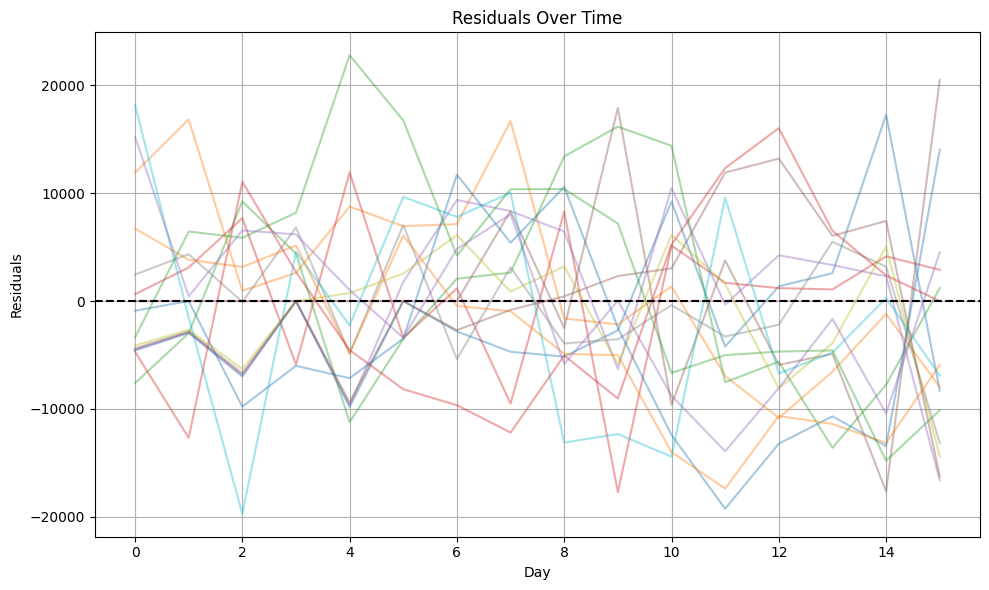

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for x in range(player_count):
    player = f"player_{x}"
    future_preds = preds[player]
    y_actual = time_series[player].iloc[-len(future_preds):].values
    y_pred = [pred[1] for pred in future_preds]
    
    residuals = y_actual - y_pred
    
    plt.plot(residuals, alpha=0.4, label=player)

plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals Over Time")
plt.xlabel("Day")
plt.ylabel("Residuals")
plt.grid(True)

plt.tight_layout()
plt.show()